# Бинарная (логистическая) регрессия в Python

**Дисциплина:** Введение в анализ больших данных

Когда отклик принимает **только два значения** (0/1), используют логистическую регрессию:

$$
P(Y=1 \mid x) = \frac{1}{1 + \exp(-(b_0 + b_1 x_1 + \ldots + b_k x_k))}
$$

Инструменты: `statsmodels` (`logit` / `probit`), метрики и ROC из **scikit-learn**.

Демо: датасет **breast cancer** (диагностика опухоли).


## 0. Импорт


In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, accuracy_score, classification_report,
    roc_curve, roc_auc_score, ConfusionMatrixDisplay,
)

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")
np.random.seed(42)


---
## 1. Данные

Отклик `target`: 0 — злокачественная, 1 — доброкачественная.  
Предикторы — несколько числовых характеристик опухоли.


In [11]:
df = pd.read_csv('datlg.csv')
y = "y"

df.head()

,Unnamed: 0,y,sex,x1,x2,x3,x4
0,1,0,0,1,0,0,0
1,2,0,0,0,1,0,1
2,3,0,0,0,1,1,0
3,4,0,1,0,1,1,0
4,5,1,1,0,0,0,0


In [12]:
print("Колонки в данных:")
print(list(df.columns))

print(f"\nРаспределение отклика '{y}':")
print(df[y].value_counts())

Колонки в данных:
['Unnamed: 0', 'y', 'sex', 'x1', 'x2', 'x3', 'x4']

Распределение отклика 'y':
y
0    199
1    104
Name: count, dtype: int64


---
## 2. Логит-модель

`smf.logit("y ~ x1 + x2 + ...", data=df).fit()`


In [30]:
X_cols = [c for c in df.columns if c != y]

predictors = " + ".join(X_cols)
f = f"{y} ~ {predictors}"
print(predictors)
m_logit = smf.logit(
    f,
    data=df,
).fit(disp=False)
print(m_logit.summary())


Unnamed: 0 + sex + x1 + x2 + x3 + x4
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  303
Model:                          Logit   Df Residuals:                      297
Method:                           MLE   Df Model:                            5
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.1609
Time:                        21:24:11   Log-Likelihood:                -163.53
converged:                       True   LL-Null:                       -194.88
Covariance Type:            nonrobust   LLR p-value:                 3.364e-12
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.6332      0.253     -2.500      0.012      -1.130      -0.137
sex           -0.5358      0.290     -1.849      0.064      -1.104       0.032
x1            -

In [32]:
coefs = {
    'sex': -0.5358,
    'x1': -1.8631,
    'x2': 1.8963,
    'x3': 0.7756,
    'x4': 0.6167
}

for name, coef in coefs.items():
    or_value = np.exp(coef)
    print(f"{name}: OR = {or_value:.3f}")

sex: OR = 0.585
x1: OR = 0.155
x2: OR = 6.661
x3: OR = 2.172
x4: OR = 1.853


### Предварительные выводы:


`LLR p-value:` 3.364e-12 | Это говорит о том, что модель отвергает H0 (все коэффициенты b(0-k) при независимых переменных равны нулю) -> p < 0.05

`p-values:`
> x1 = 0.013;
>
> x2 = 0.000

`COEFS`:
> x1 = -1.8631
>
> x2 = 1.8963

Это самые меньшие значения (p < 0.05), они статистически значимы. При этом коэффициенты вляются сильне всего среди них, а также у x1 отрицательный коэф.


### Пробит-модель

Тот же набор предикторов, другая link-функция.


In [33]:
m_probit = smf.probit(
    f,
    data=df,
).fit(disp=False)
print(m_probit.summary())


                          Probit Regression Results                           
Dep. Variable:                      y   No. Observations:                  303
Model:                         Probit   Df Residuals:                      297
Method:                           MLE   Df Model:                            5
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.1592
Time:                        21:25:39   Log-Likelihood:                -163.86
converged:                       True   LL-Null:                       -194.88
Covariance Type:            nonrobust   LLR p-value:                 4.597e-12
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3939      0.153     -2.574      0.010      -0.694      -0.094
sex           -0.3157      0.173     -1.825      0.068      -0.655       0.023
x1            -0.9762      0.354     -2.761      0.0

### Выводы
Снова значимость присутствует у тех же `x1` и `x2`, однако между этими коэффициентами нет такой сильной разницы, как в логите. Также сами коэффициенты меньше в пробите, чем в логите. На практике допускают разницу между коэффициентами логит и пробит моделями в `1.6-1.8` раз.

### Значимость модели в целом (likelihood-ratio)


In [21]:
lr = 2 * (m_logit.llf - m_logit.llnull)
p_lr = stats.chi2.sf(lr, m_logit.df_model)
print(f"LR chi2 = {lr:.2f}, df = {m_logit.df_model:.0f}, p = {p_lr:.4e}")
print("модель значима" if p_lr < 0.05 else "модель не значима")


LR chi2 = 62.70, df = 5, p = 3.3645e-12
модель значима


---
## 3. Матрица неточностей

Порог по умолчанию: 0.5.

| | прогноз 0 | прогноз 1 |
|--|-----------|-----------|
| факт 0 | TN | FP |
| факт 1 | FN | TP |

- **Accuracy** = (TP+TN)/N  
- **Sensitivity (Recall)** = TP/(TP+FN)  
- **Specificity** = TN/(TN+FP)


Confusion matrix:
 [[184  15]
 [ 61  43]]
Accuracy = 0.7492
              precision    recall  f1-score   support

           0      0.751     0.925     0.829       199
           1      0.741     0.413     0.531       104

    accuracy                          0.749       303
   macro avg      0.746     0.669     0.680       303
weighted avg      0.748     0.749     0.727       303



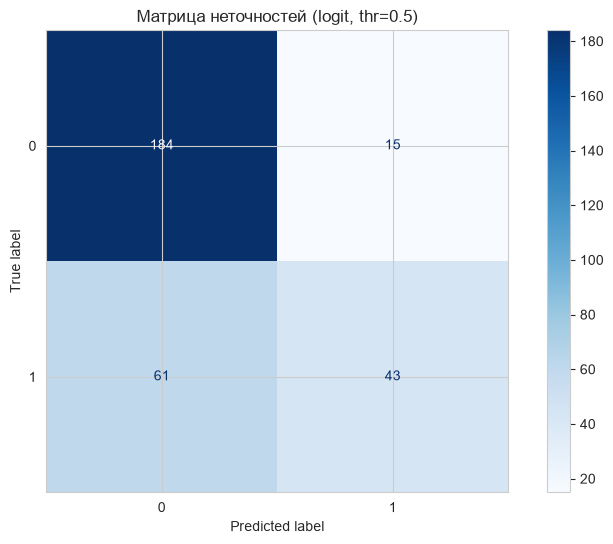

In [59]:
prob = m_logit.predict(df)
pred = (prob >= 0.5).astype(int)

cm = confusion_matrix(df[y], pred)
print("Confusion matrix:\n", cm)
print("Accuracy =", round(accuracy_score(df[y], pred), 4))
print(classification_report(df[y], pred, digits=3))

ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(cmap="Blues")
plt.title("Матрица неточностей (logit, thr=0.5)")
plt.show()


### числа

TN = 184

TP = 43

FN = 61 - ай ай ай

FP = 15 - ай ай

precision (точность) - у обоих случаев одинакова практически. Полнота лучше у `y="0"`, то есть не нужно делать операции (интересно). В любом случае, это не очень хорошо, происходит это вероятно из-за дисбаланса классов, потому что по логике не часто приходится прибегать к операции.

---
## 4. ROC-кривая и AUC

Чем ближе кривая к верхнему левому углу и чем больше **AUC**, тем лучше.  
AUC ≈ 0.5 — как случайное угадывание; ближе к 1 — сильная модель.


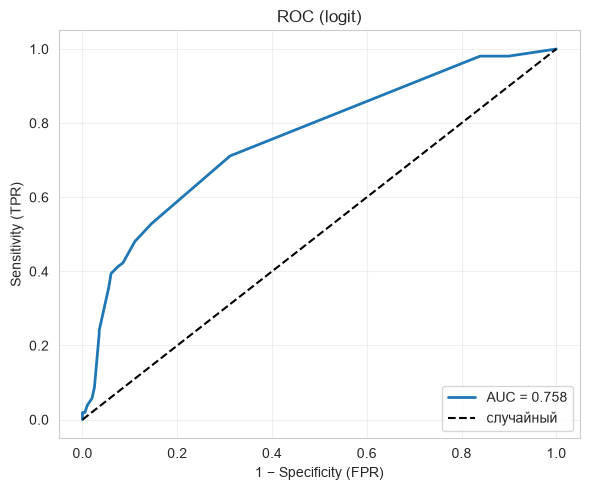

AUC = 0.7579


In [38]:
fpr, tpr, _ = roc_curve(df[y], prob)
auc = roc_auc_score(df[y], prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", label="случайный")
plt.xlabel("1 − Specificity (FPR)")
plt.ylabel("Sensitivity (TPR)")
plt.title("ROC (logit)")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(f"AUC = {auc:.4f}")


# Выводы
AUC > 0.5 и ближе к 1, чем к 0.5, средняя модель. Поведение кривой далеко от прямой (случайный подбор). Скорее всего с 75% модель правильно классифицирует больных.

---
## 5. Train / test

Правильный порядок: обучить на train, оценить на **test** (и при желании на train для сравнения).


In [51]:
train, test = train_test_split(
    df, test_size=0.2, random_state=7, stratify=df[y]
)

print("train:", train.shape, "test:", test.shape)
print("доля y=1 train:", round(train[y].mean(), 3))
print("доля y=1 test :", round(test[y].mean(), 3))


train: (242, 7) test: (61, 7)
доля y=1 train: 0.343
доля y=1 test : 0.344


In [52]:
model = smf.logit(
    f,
    data=train,
).fit(disp=False)
print(model.summary())


                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  242
Model:                          Logit   Df Residuals:                      236
Method:                           MLE   Df Model:                            5
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.1841
Time:                        21:40:13   Log-Likelihood:                -126.96
converged:                       True   LL-Null:                       -155.60
Covariance Type:            nonrobust   LLR p-value:                 4.412e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.7425      0.285     -2.606      0.009      -1.301      -0.184
sex           -0.4716      0.327     -1.442      0.149      -1.112       0.169
x1            -2.2651      1.037     -2.185      0.0

# Выводы
Как видим, разделение выборки на тестовую и обучающую оказывает позитивное влияние на модель (как ни странно). Если раньше значимы были только `x1` и `x2`, то сейчас в этот клуб классных ребят присоединился `x4`. Правда скорее всего это погрешность выборки, а не факт, как у `x1` и `x2`

In [53]:
def evaluate(model, data, name):
    y = data["y"]
    p = model.predict(data)
    yhat = (p >= 0.5).astype(int)
    acc = accuracy_score(y, yhat)
    auc = roc_auc_score(y, p)
    cm = confusion_matrix(y, yhat)
    print(f"=== {name} ===")
    print("CM:\n", cm)
    print(f"Accuracy = {acc:.4f}, AUC = {auc:.4f}")
    print(classification_report(y, yhat, digits=3))
    return p, auc

p_tr, auc_tr = evaluate(model, train, "TRAIN")
p_te, auc_te = evaluate(model, test, "TEST")


=== TRAIN ===
CM:
 [[149  10]
 [ 48  35]]
Accuracy = 0.7603, AUC = 0.7691
              precision    recall  f1-score   support

           0      0.756     0.937     0.837       159
           1      0.778     0.422     0.547        83

    accuracy                          0.760       242
   macro avg      0.767     0.679     0.692       242
weighted avg      0.764     0.760     0.738       242

=== TEST ===
CM:
 [[36  4]
 [14  7]]
Accuracy = 0.7049, AUC = 0.7119
              precision    recall  f1-score   support

           0      0.720     0.900     0.800        40
           1      0.636     0.333     0.438        21

    accuracy                          0.705        61
   macro avg      0.678     0.617     0.619        61
weighted avg      0.691     0.705     0.675        61



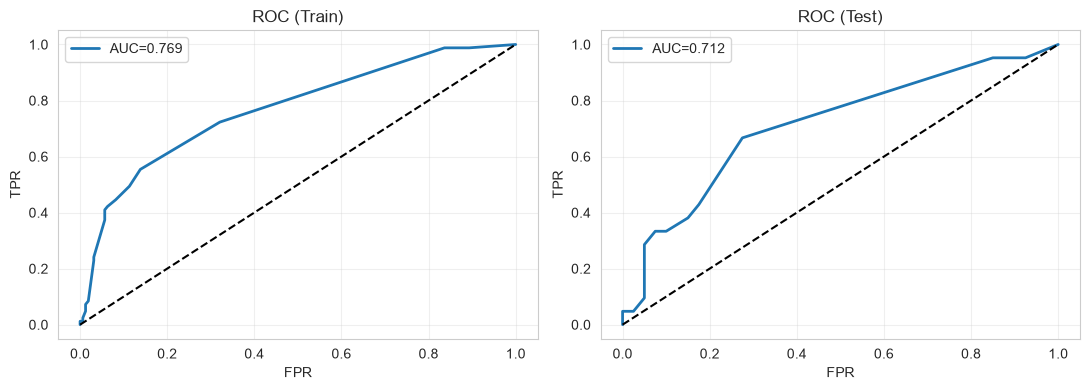

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, data, p, title, auc_v in [
    (axes[0], train, p_tr, "Train", auc_tr),
    (axes[1], test, p_te, "Test", auc_te),
]:
    fpr, tpr, _ = roc_curve(data[y], p)
    ax.plot(fpr, tpr, lw=2, label=f"AUC={auc_v:.3f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_title(f"ROC ({title})")
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Выводы

### 1. TRAIN / TEST
Показатели у выборки TRAIN закономерно лучше, чем у TEST, главное понять, насколько критичны отклонения.

Начнём с коэффициентов и выводов по ним.

`Основные коэффициенты:`
> x1 = -2.2651 | p = 0.029 - Сильное отриц. влияние
>
> x2 = 1.9923  | p = 0.000 - Сильное положительное влияние
>
> x4 = 1.1892  | p = 0.026 - Положительное влияние

Вывод в том, что 3 переменных значимы, и по-своему влияют, а остальные, которых нет в топе, можно и исключить.

### 2. ROC + AUC
Показатели в recall для train и test сохраняют один паттерн, людей, которым не нужна операция получается определить чаще, чем тех, которым не нужна, вероятно есть дисбаланс классов.

Также можно заметить, что на тестовой выборке сильно отличается AUC (train: 0.7691 | test: 0.7119), это не переобучение, вполне закономерно.

> Среди метрик `precision/recall` есть отличие, в тестовой выборке значения для класса 1 упали сильнее, чем в классе 0, что говорит о том, что в выборку попало мало записей класса 1.

### 3. ROC + AUC графики
Очень рваный график на тестовой, но опять же, из-за размера выборки - это закономерно, модель хуже справляется на тестовых данных судя по графику и метрике AUC.
#####
###### В графике ниже видно, что дисбаланс классов 2:1 (не делать/делать)

([<matplotlib.axis.XTick at 0x21f5debb4d0>,
 [Text(0, 0, '0 (не делать)'), Text(1, 0, '1 (делать)')])

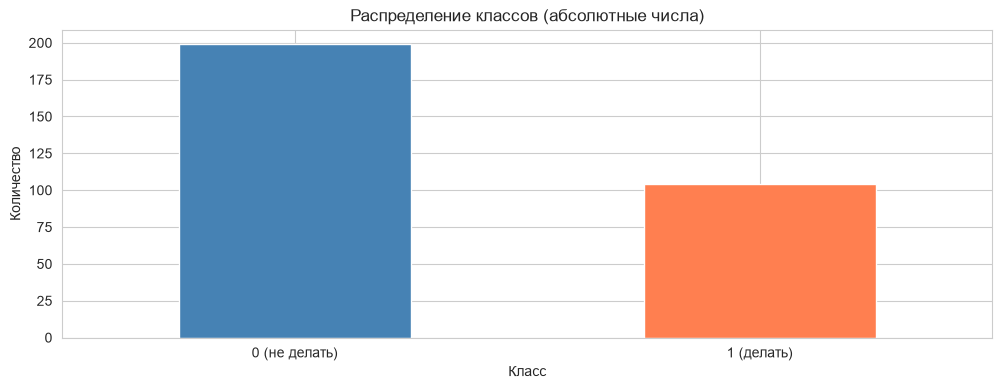

In [78]:
plt.figure(figsize=(12, 4))
class_counts = df["y"].value_counts()
class_counts.plot(kind='bar', color=['steelblue', 'coral'])
plt.title("Распределение классов (абсолютные числа)")
plt.xlabel("Класс")
plt.ylabel("Количество")
plt.xticks(ticks=[0, 1], labels=['0 (не делать)', '1 (делать)'], rotation=0)


### Как описать результаты

1. Значимость коэффициентов (p < 0.05) и знак связи.  
2. Метрики на **train** и **test** (accuracy, sensitivity, specificity, AUC).  
3. Нет ли сильного проседания на test (переобучение).  
4. Форма ROC и величина AUC (ориентиры: >0.7 приемлемо, >0.8 хорошо).

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Логит | `smf.logit("y ~ x1 + x2", data=df).fit()` |
| Пробит | `smf.probit("y ~ x1 + x2", data=df).fit()` |
| Вероятности | `model.predict(df)` |
| Класс (порог 0.5) | `(prob >= 0.5).astype(int)` |
| Confusion matrix | `confusion_matrix(y, pred)` |
| Accuracy | `accuracy_score(y, pred)` |
| ROC / AUC | `roc_curve`, `roc_auc_score` |
| Train/test | `train_test_split(..., stratify=y)` |
